In [1]:

%cd ..

from pathlib import Path
print(Path.cwd())

import numpy as np
import matplotlib.pyplot as plt

from hardware import ammeter, ammeter_uncertainty, gaussmeter, gaussmeter_uncertainty, horizontal_coils, vertical_coils, modulation_coils, horizontal_coils_uncertainty, vertical_coils_uncertainty, modulation_coils_uncertainty
from scope_header import DSOX1204G, self_test, load_waveforms


plt.rcParams.update({
    "font.sans-serif": ["Cabin", "Libertinus Sans", "DejaVu Sans"],
    "font.serif": ["Libertinus Serif"],
    "font.family": "sans-serif",
    "font.style": "normal",
    "font.weight": "normal",
    "font.size": 14,
    "axes.labelsize": 16,
    "axes.titlesize": 18,
    "axes.titleweight": "bold",
    "axes.labelweight": "normal",
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 14,
    "legend.title_fontsize": 14,
    "figure.titlesize": 18,
    "figure.titleweight": "bold",
    "mathtext.fontset": "cm",
    "mathtext.default": "it",
    "axes.unicode_minus": False,
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.titlecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "legend.edgecolor": "black",
})
%matplotlib inline

from scipy.optimize import curve_fit
from scipy import signal

# scope = DSOX1204G()


c:\Users\njwan\OneDrive - University of Toronto\Documents\Year 3\3F\PHY327\1 - Optical Pumping in Rubidium\code
c:\Users\njwan\OneDrive - University of Toronto\Documents\Year 3\3F\PHY327\1 - Optical Pumping in Rubidium\code


# single shot

In [2]:
%matplotlib ipympl

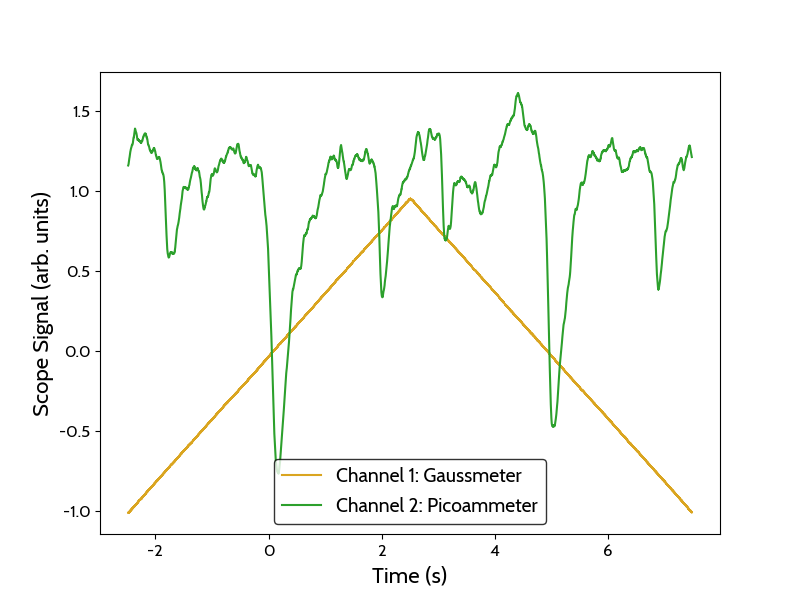

In [3]:
data = load_waveforms("data/25/600kHz_486.npz")
t, V1, V2 = data[1][0], data[1][1], data[2][1]


N = 200
t = np.convolve(t, np.ones(N)/N, mode='valid')
V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
V2 = np.convolve(V2, np.ones(N)/N, mode='valid')

fig0, ax0 = plt.subplots(figsize=(8, 6))
ax0.plot(t, V1, label='Channel 1: Gaussmeter', color='goldenrod')
ax0.plot(t, V2*5-2, label='Channel 2: Picoammeter', color='tab:green')
ax0.set_xlabel('Time (s)')
ax0.set_ylabel('Scope Signal (arb. units)')
ax0.legend()


# automating it

In [4]:
def plot_average_2s(data_range, date, filename):
    transmissions_forward = []
    transmissions_backward = []
    for data_num in data_range:
        data = load_waveforms(f"data/{date}/{filename}_{data_num}.npz")
        t, V1, V2 = data[1][0], data[1][1], data[2][1]
        N = 800
        t = np.convolve(t, np.ones(N)/N, mode='valid')
        V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
        V2 = np.convolve(V2, np.ones(N)/N, mode='valid')

        mask_forward = (t > -1) & (t < 1)
        mask_backward = (t > 1) & (t < 3)

        field_forward = gaussmeter(V1[mask_forward]*1e3)
        field_backward = gaussmeter(V1[mask_backward]*1e3)

        transmission_forward = ammeter(V2[mask_forward]*1e3)
        transmission_backward = ammeter(V2[mask_backward]*1e3)
        transmissions_forward.append(transmission_forward)
        transmissions_backward.append(transmission_backward)

    transmissions_forward = np.array(transmissions_forward)
    transmissions_backward = np.array(transmissions_backward)
    average_transmissions_forward = np.mean(transmissions_forward, axis=0)
    average_transmissions_backward = np.mean(transmissions_backward, axis=0)
    
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.plot(field_forward, average_transmissions_forward, label='Average Transmission (Forward)', color='tab:blue', marker = '.', markersize = 1)
    ax.plot(field_backward, average_transmissions_backward, label='Average Transmission (Backward)', color='tab:red', marker = '.', markersize = 1)
    ax.set_xlabel('Magnetic Field (G)')
    ax.set_ylabel('Transmission (arb. units)')
    ax.legend(loc = "upper right")

def plot_average_5s(data_range, date, filename):
    transmissions_forward = []
    transmissions_backward = []
    for data_num in data_range:
        data = load_waveforms(f"data/{date}/{filename}_{data_num}.npz")
        t, V1, V2 = data[1][0], data[1][1], data[2][1]
        N = 400
        t = np.convolve(t, np.ones(N)/N, mode='valid')
        V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
        V2 = np.convolve(V2, np.ones(N)/N, mode='valid')

        mask_forward = (t > -2.5) & (t < 2.5)
        mask_backward = (t > 2.5) & (t < 2.5 + 5)

        field_forward = gaussmeter(V1[mask_forward]*1e3)
        field_backward = gaussmeter(V1[mask_backward]*1e3)

        transmission_forward = ammeter(V2[mask_forward]*1e3)
        transmission_backward = ammeter(V2[mask_backward]*1e3)
        transmissions_forward.append(transmission_forward)
        transmissions_backward.append(transmission_backward)

    transmissions_forward = np.array(transmissions_forward)
    transmissions_backward = np.array(transmissions_backward)
    average_transmissions_forward = np.mean(transmissions_forward, axis=0)
    average_transmissions_backward = np.mean(transmissions_backward, axis=0)
    
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.plot(field_forward, average_transmissions_forward, label='Average Transmission (Forward)', color='tab:blue', marker = '.', markersize = 1)
    ax.plot(field_backward, average_transmissions_backward, label='Average Transmission (Backward)', color='tab:red', marker = '.', markersize = 1)
    ax.set_xlabel('Magnetic Field (G)')
    ax.set_ylabel('Transmission (arb. units)')
    ax.legend(loc = "upper right")


# Power test

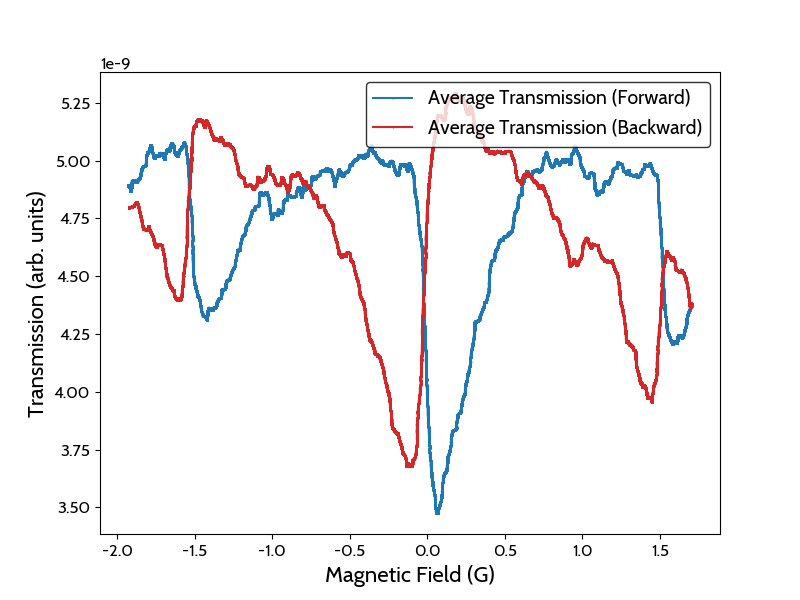

In [5]:
plot_average_2s(range(184, 189), "25", "power_7vpp")

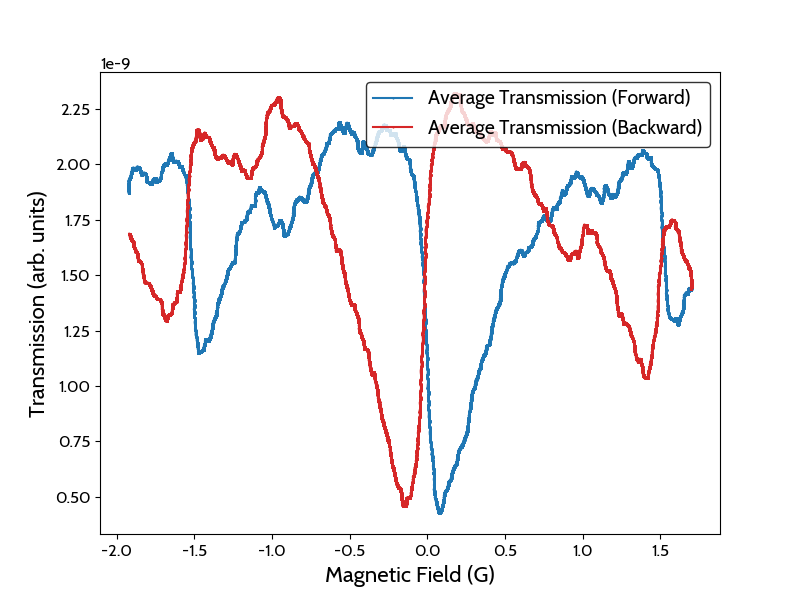

In [6]:
plot_average_2s(range(194, 199), "25", "power_8vpp") # should be 9Vpp

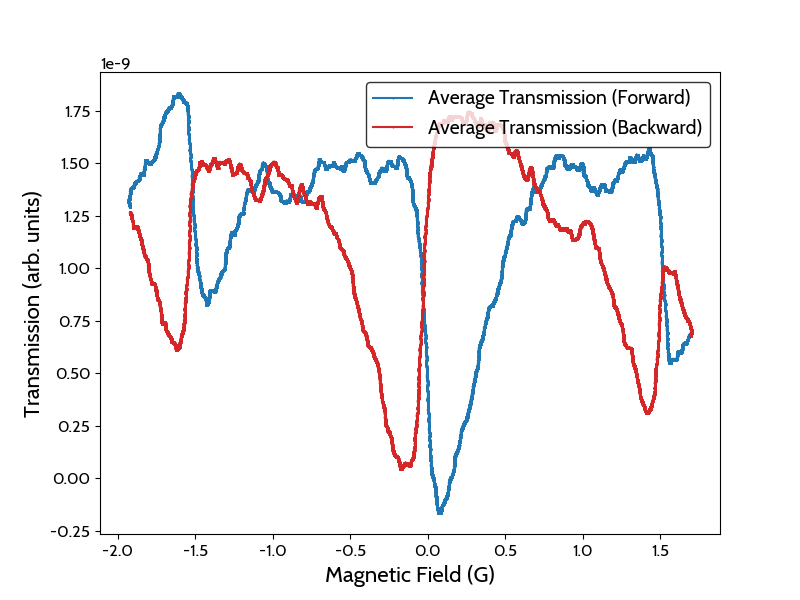

In [7]:
plot_average_2s(range(199, 204), "25", "power_10vpp") 

# Tests

In [ ]:
plot_average_5s(range(204, 227), "25", "test")

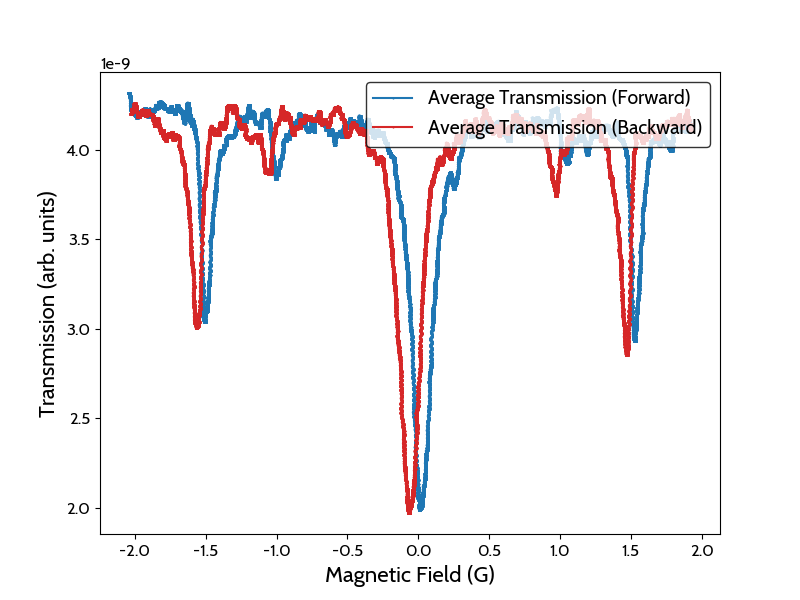

In [ ]:
plot_average_5s(range(229, 239), "25", "test")

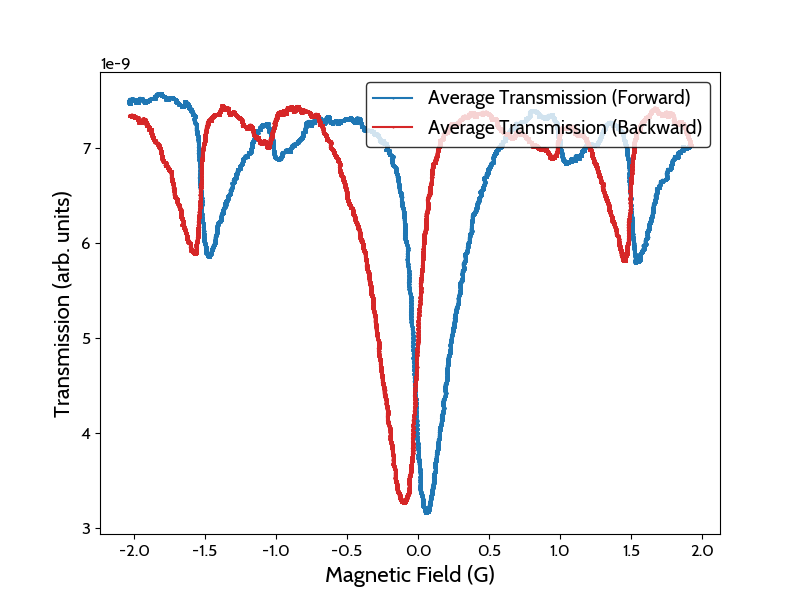

In [ ]:
plot_average_5s(range(239, 249), "25", "test_fine")

# varying rf

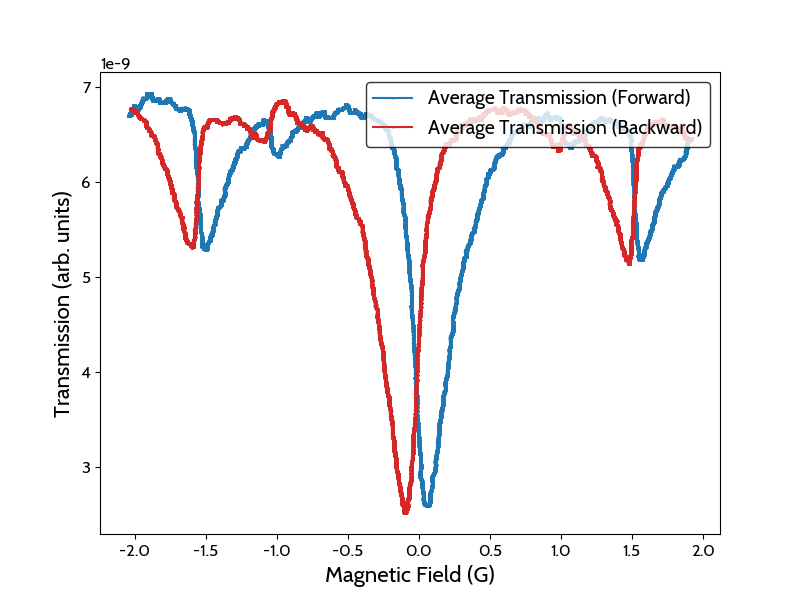

In [ ]:
# 620 kHz
plot_average_5s(range(249, 259), "25", "620kHz")

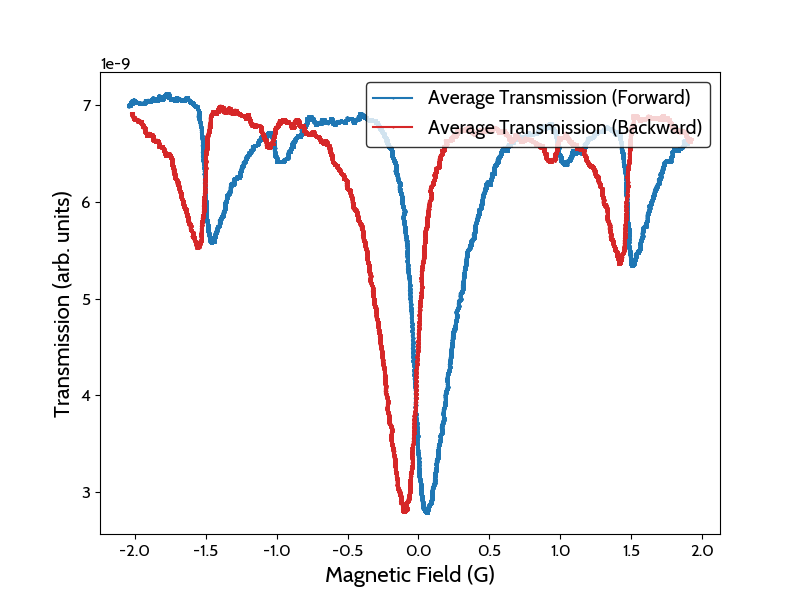

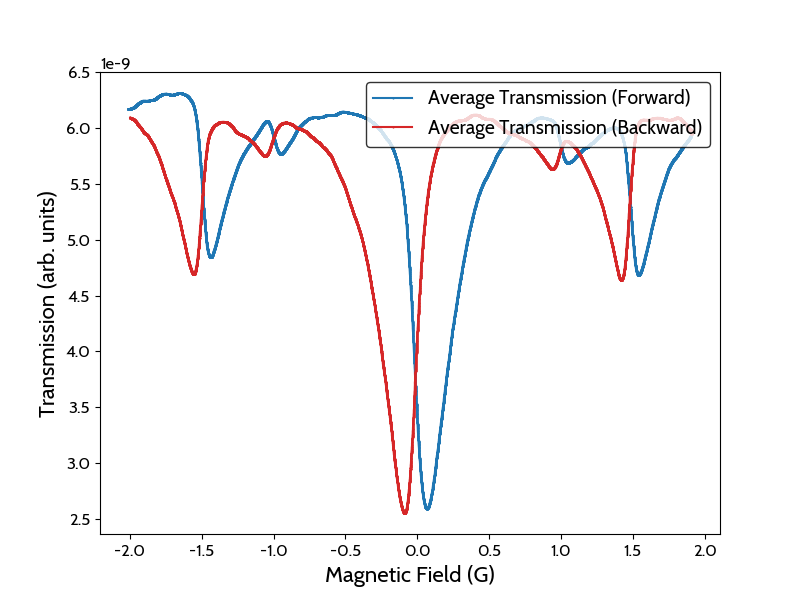

In [ ]:
# 600 kHz
plot_average_5s(range(259, 269), "25", "600kHz")
plot_average_5s(range(474, 504), "25", "600kHz")

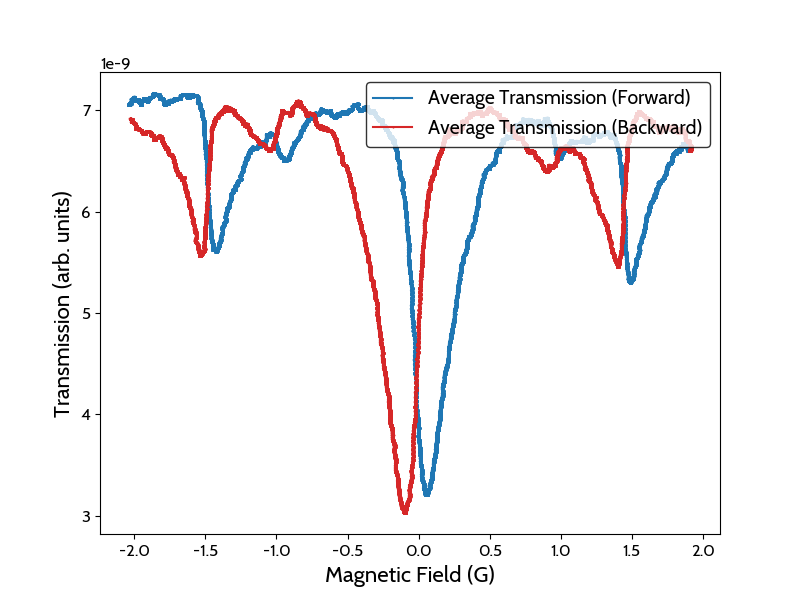

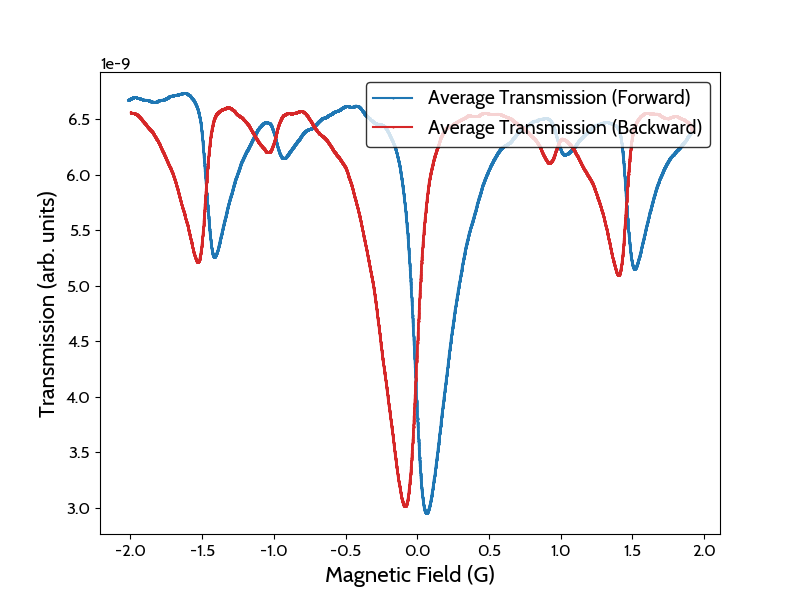

In [ ]:
# 590 kHz
plot_average_5s(range(269, 279), "25", "590kHz")
plot_average_5s(range(444, 474), "25", "590kHz")

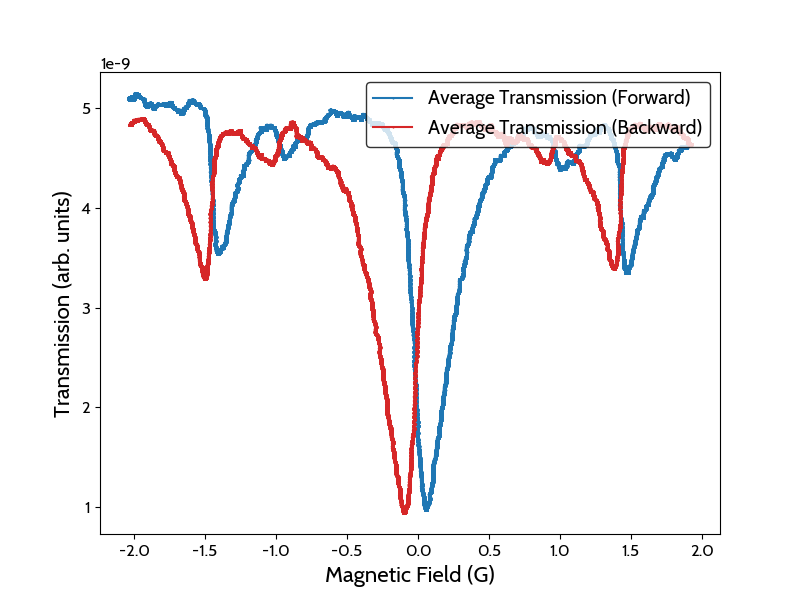

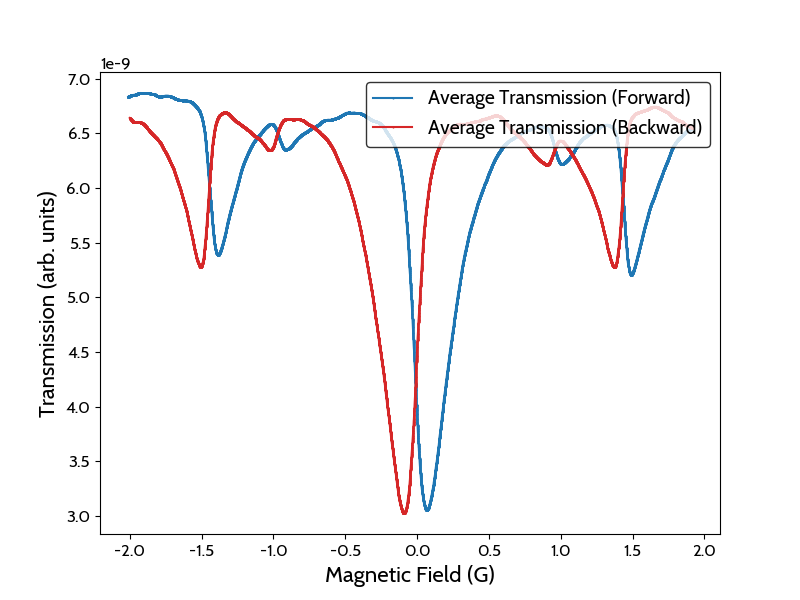

In [ ]:
# 580 kHz
plot_average_5s(range(279, 289), "25", "580kHz")
plot_average_5s(range(414, 444), "25", "580kHz")

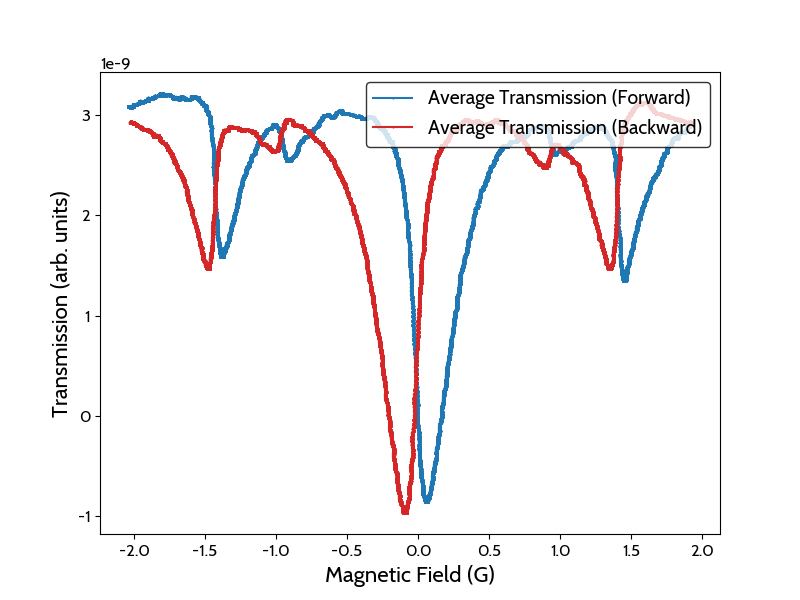

In [ ]:
# 570 kHz
plot_average_5s(range(289, 319), "25", "570kHz")

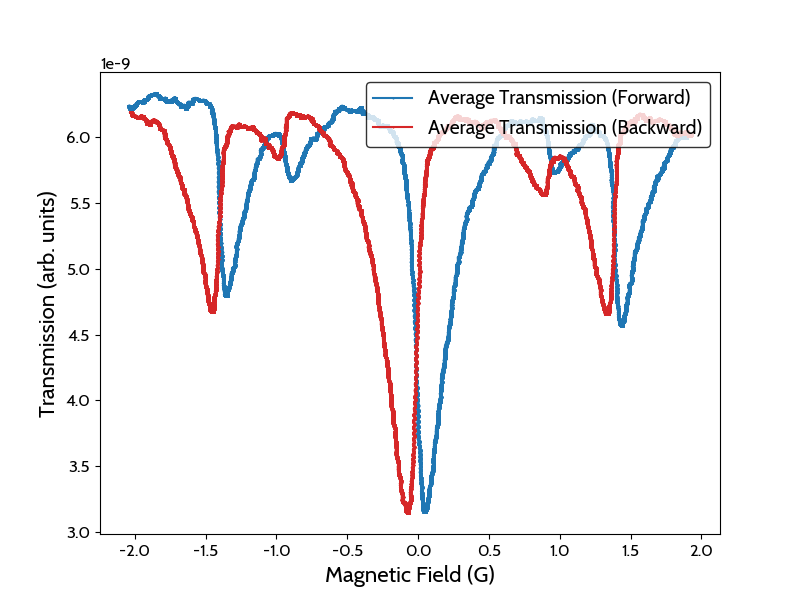

In [ ]:
# 560 kHz
plot_average_5s(range(349, 374), "25", "560kHz")

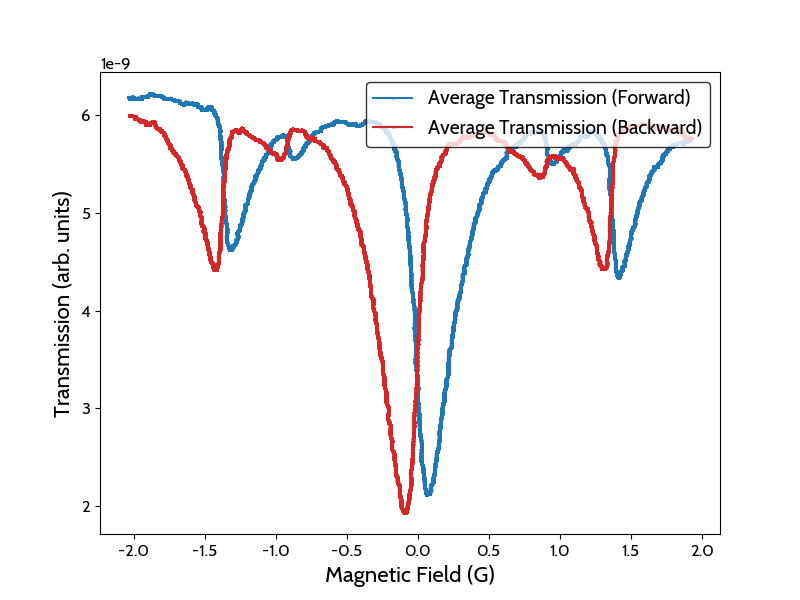

In [ ]:
# 550 kHz
plot_average_5s(range(319, 349), "25", "550kHz")

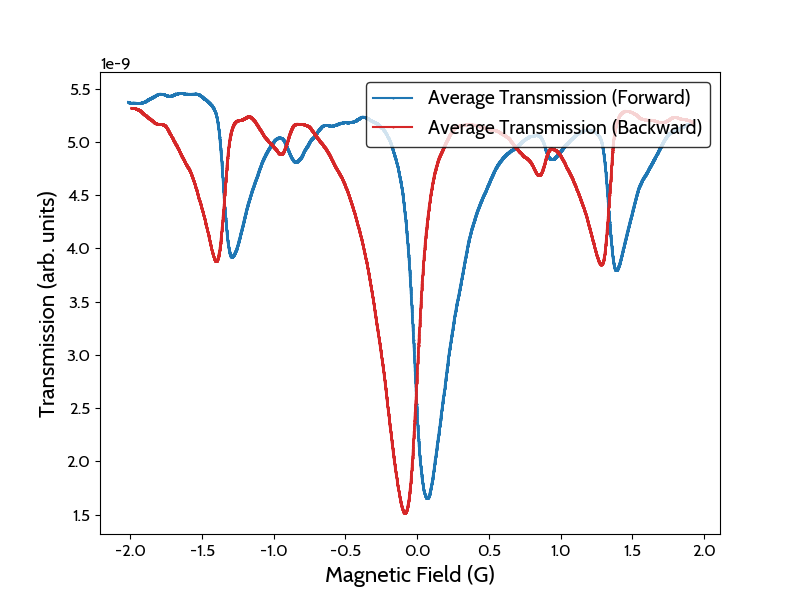

In [ ]:
# 540 kHz
plot_average_5s(range(384, 414), "25", "540kHz")